# ESMValTool wrapper test (`rf_shap`)

This notebook tests the same code path as `esmvaltool/diag_scripts/rf_shap/diagnostic.py`, **without** needing `esmvaltool run` or a CMOR/DRS tree.

What it checks:

1. Pretend ESMValCore wrote **one NetCDF per variable** (including `latitude`/`longitude` names).
2. Load those files with `open_field` / `load_xy_from_files` (the diagnostic helpers).
3. Run `run_pipeline_on_cubes` (ExtraTrees, time split, SHAP restored to a cube).
4. Plot metrics, maps, importance, SHAP, ALE, ICE+PDP.
5. Optionally try local ACCESS-CM2 files if they exist.

Start Jupyter from the repository root:

```bash
cd /path/to/RF_SHAP_ESMValTool
PYTHONPATH=src jupyter notebook examples/esmvaltool_test.ipynb
```

The last cell is optional and is skipped automatically if ACCESS-CM2 is missing.

## Import through ESMValTool

After `bash esmvaltool/install_links.sh`, the functions live under `esmvaltool.rf_shap` and `esmvaltool.diag_scripts.rf_shap`. This cell is skipped if that link is not installed.

In [1]:
try:
    import esmvaltool
    print("esmvaltool", esmvaltool.__version__)
    print("esmvaltool.rf_shap", esmvaltool.rf_shap)
    from esmvaltool.rf_shap import DiagnosisPipeline as DP1
    from esmvaltool.diag_scripts.rf_shap.models import build_model
    from esmvaltool.rf_shap.cube import align_xy
    from esmvaltool.diag_scripts.rf_shap.explain import compute_shap
    print("DiagnosisPipeline", DP1)
    print("build_model", build_model)
    print("align_xy", align_xy)
    print("compute_shap", compute_shap)
except Exception as exc:
    print("esmvaltool.rf_shap not installed yet:", type(exc).__name__, exc)
    print("Run: ESMVALTOOL_PYTHON=... python bash esmvaltool/install_links.sh")

esmvaltool 2.15.0
esmvaltool.rf_shap <module 'esmvaltool.rf_shap' from '/opt/miniconda3/envs/esmvaltool/lib/python3.12/site-packages/esmvaltool/rf_shap/__init__.py'>
DiagnosisPipeline <class 'rf_shap.pipeline.DiagnosisPipeline'>
build_model <function build_model at 0x179902660>
align_xy <function align_xy at 0x169f68c20>
compute_shap <function compute_shap at 0x179901d00>


In [2]:
from pathlib import Path
import sys
import tempfile

root = Path.cwd().resolve()
if (root / "src" / "rf_shap").exists():
    sys.path.insert(0, str(root / "src"))
elif (root.parent / "src" / "rf_shap").exists():
    sys.path.insert(0, str(root.parent / "src"))
    root = root.parent

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from rf_shap.esmval_bridge import load_xy_from_files, open_field, run_pipeline_on_cubes, save_result_files
from rf_shap.plot import (
    plot_ale,
    plot_cube_maps,
    plot_error_map,
    plot_ice_pdp,
    plot_importance_bars,
    plot_pred_scatter,
    plot_shap_maps,
    plot_shap_summary,
    plot_spatial_mean_timeseries,
)
from rf_shap.predict.reconstruct import reconstruct_prediction
from rf_shap.synthetic import make_synthetic_cubes

print("repo", root)
print("rf_shap import ok")

repo /Users/huangfeini/Documents/rf_shap
rf_shap import ok


## 1. Fake ESMValTool preprocessor files

ESMValCore writes one file per variable. Axis names are often `latitude`/`longitude`, not `lat`/`lon`. We write that layout so `open_field` has to rename axes.

In [4]:
x, y = make_synthetic_cubes(n_time=18, n_lat=6, n_lon=8, seed=7)
work = Path(tempfile.mkdtemp(prefix="rf_shap_esmval_"))
print("temp preprocessor dir:", work)

def write_esmval_like(da: xr.DataArray, path: Path, name: str) -> Path:
    out = da.rename(name).rename({"lat": "latitude", "lon": "longitude"})
    ds = out.to_dataset(name=name)
    ds.to_netcdf(path)
    return path

x_files = {}
for name in x.data_vars:
    x_files[name] = str(write_esmval_like(x[name], work / f"{name}.nc", name))
y_file = str(write_esmval_like(y["obs"], work / "obs.nc", "obs"))
x_files, y_file

temp preprocessor dir: /var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/rf_shap_esmval_2ag48kwi


({'tas': '/var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/rf_shap_esmval_2ag48kwi/tas.nc',
  'pr': '/var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/rf_shap_esmval_2ag48kwi/pr.nc',
  'huss': '/var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/rf_shap_esmval_2ag48kwi/huss.nc'},
 '/var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/rf_shap_esmval_2ag48kwi/obs.nc')

## 2. Load with the diagnostic helpers

This is what `diagnostic.py` does after `cfg["input_data"]` or `x_files`/`y_file` is filled.

In [6]:
sample = open_field(x_files["tas"], "tas")
assert tuple(sample.dims) == ("time", "lat", "lon"), sample.dims
print("open_field renamed axes:", sample.dims, sample.shape)

X, Y = load_xy_from_files(x_files, y_file, y_name="obs")
print("X", dict(X.sizes), list(X.data_vars))
print("Y", dict(Y.sizes), list(Y.data_vars))
display(X)
display(Y)

open_field renamed axes: ('time', 'lat', 'lon') (18, 6, 8)
X {'time': 18, 'lat': 6, 'lon': 8} ['tas', 'pr', 'huss']
Y {'time': 18, 'lat': 6, 'lon': 8} ['obs']


<xarray.Dataset> Size: 21kB
Dimensions:  (time: 18, lat: 6, lon: 8)
Coordinates:
  * time     (time) datetime64[ns] 144B 2000-01-01 2000-02-01 ... 2001-06-01
  * lat      (lat) float64 48B 10.0 18.0 26.0 34.0 42.0 50.0
  * lon      (lon) float64 64B 70.0 78.57 87.14 95.71 104.3 112.9 121.4 130.0
Data variables:
    tas      (time, lat, lon) float64 7kB 10.2 10.23 10.17 ... 15.25 15.08 14.95
    pr       (time, lat, lon) float64 7kB 2.892 3.018 3.192 ... 1.079 1.24 1.184
    huss     (time, lat, lon) float64 7kB 5.311 5.188 5.339 ... 5.391 5.47 5.439

<xarray.Dataset> Size: 7kB
Dimensions:  (time: 18, lat: 6, lon: 8)
Coordinates:
  * time     (time) datetime64[ns] 144B 2000-01-01 2000-02-01 ... 2001-06-01
  * lat      (lat) float64 48B 10.0 18.0 26.0 34.0 42.0 50.0
  * lon      (lon) float64 64B 70.0 78.57 87.14 95.71 104.3 112.9 121.4 130.0
Data variables:
    obs      (time, lat, lon) float64 7kB 7.768 8.17 8.101 ... 9.349 9.308 9.217

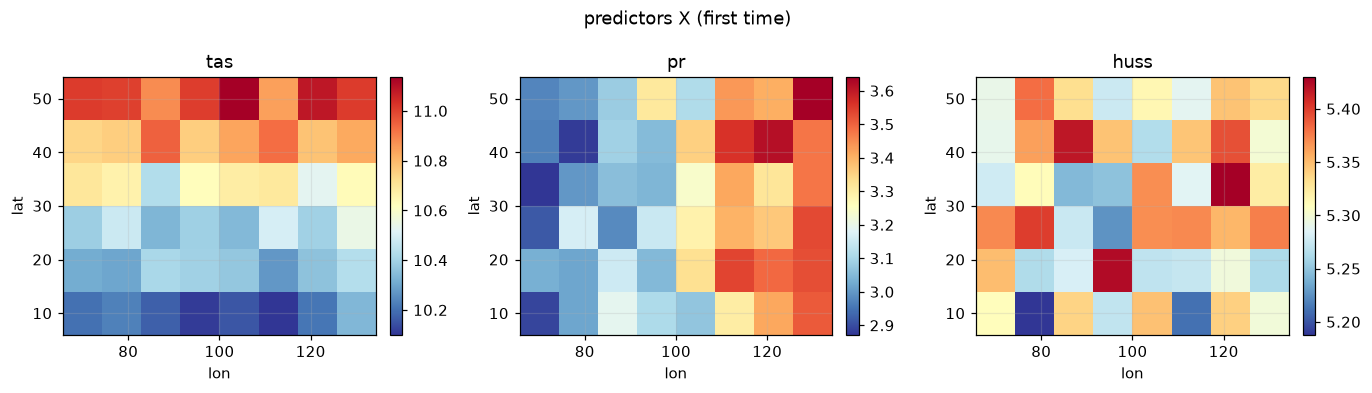

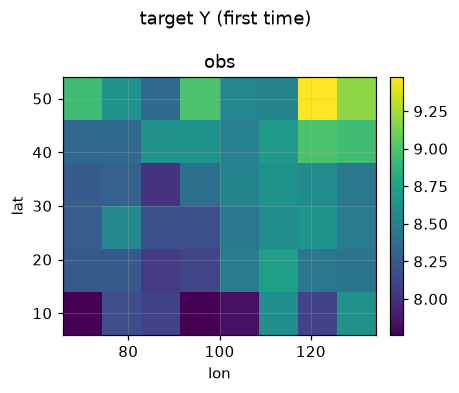

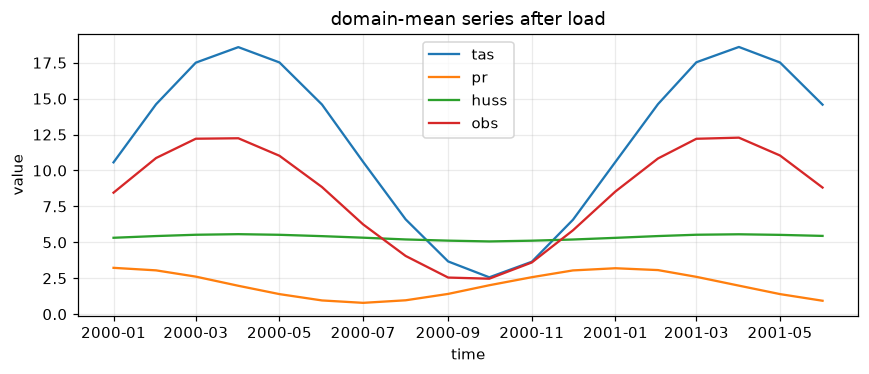

In [7]:
fig = plot_cube_maps(X, time_index=0, title="predictors X (first time)")
plt.show()
fig = plot_cube_maps(Y, time_index=0, cmap="viridis", title="target Y (first time)")
plt.show()
fig = plot_spatial_mean_timeseries(xr.merge([X, Y]), title="domain-mean series after load")
plt.show()

## 3. Run the ESMValTool pipeline wrapper

Settings are a smaller version of the recipe `scripts.rf_shap.rf_shap` block so the notebook finishes quickly.

In [8]:
override = {
    "seed": 7,
    "x_transform": {"mode": "raw"},
    "split": {"method": "time", "test_size": 0.25},
    "sampling": {"method": "random", "n_samples": 400},
    "model": {
        "name": "extra_trees",
        "params": {"n_estimators": 80, "max_depth": 8, "n_jobs": -1},
    },
    "explain": {
        "permutation_n_repeats": 2,
        "shap": {"enabled": True, "method": "auto", "max_samples": 250, "background_size": 40},
        "ice_n_samples": 20,
        "pdp_grid": 10,
    },
}
result = run_pipeline_on_cubes(X, Y, override=override)
metrics = pd.Series(result.metrics).to_frame("value")
display(metrics)
print("features:", result.artifacts.get("features"))
print("prediction cube", None if result.prediction_cube is None else result.prediction_cube.shape)
print("shap cube", None if result.shap_cube is None else list(result.shap_cube.data_vars))

IPython could not be loaded!


,value
n,192.000000
r2,0.979451
rmse,0.206492
mae,0.168276
bias,-0.005425
ubrmse,0.206420
nse,0.979451
kge,0.964157
pearson_r,0.989980
mape,0.015577


features: ['tas', 'pr']
prediction cube (18, 6, 8)
shap cube ['tas', 'pr']


## 4. Prediction: scatter and restored maps

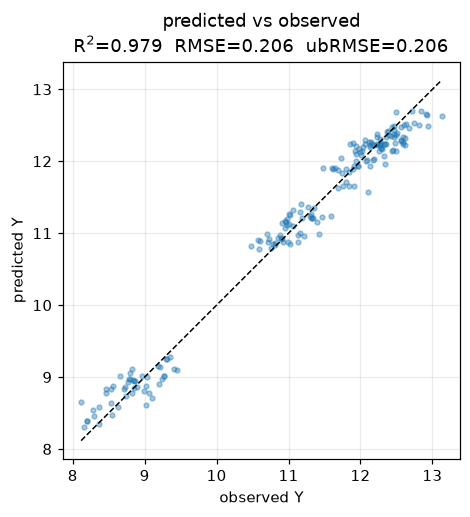

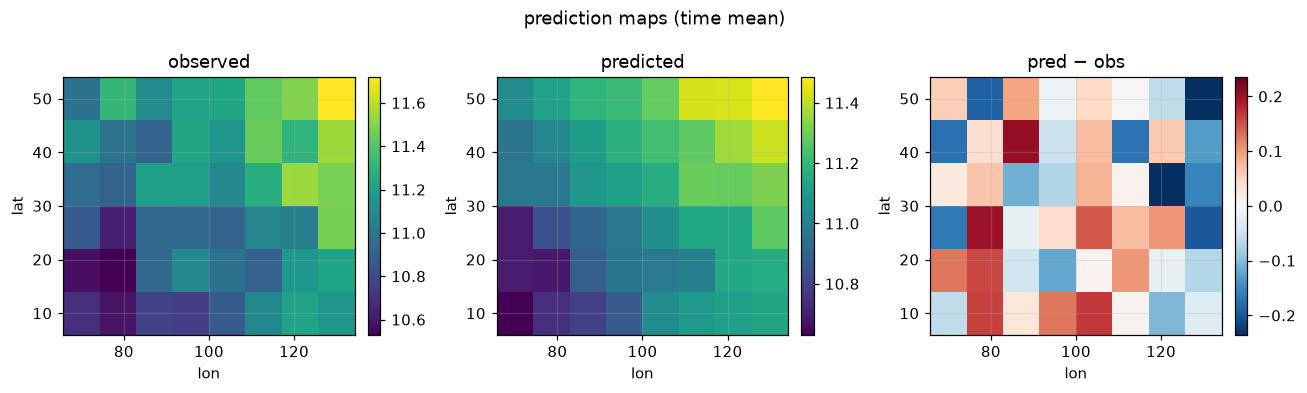

In [9]:
fig = plot_pred_scatter(result.split.test.y, result.prediction, result.metrics)
plt.show()
if result.prediction_cube is not None:
    obs_cube = reconstruct_prediction(result.split.test.y, result.split.test, name="obs")
    fig = plot_error_map(obs_cube, result.prediction_cube)
    plt.show()
else:
    print("prediction cube missing")

## 5. Explanation: importance, SHAP cubes, ALE, ICE+PDP

,feature,importance
0,tas,0.933064
1,pr,0.066936


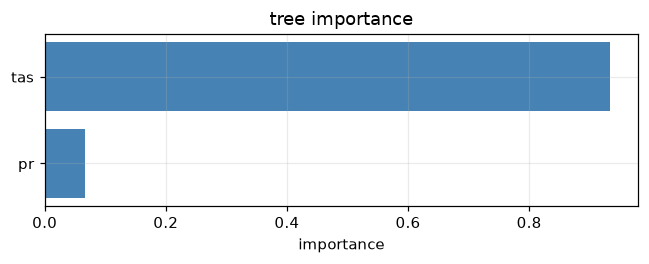

,feature,importance,std
0,tas,0.830908,0.011178
1,pr,0.375449,0.011818


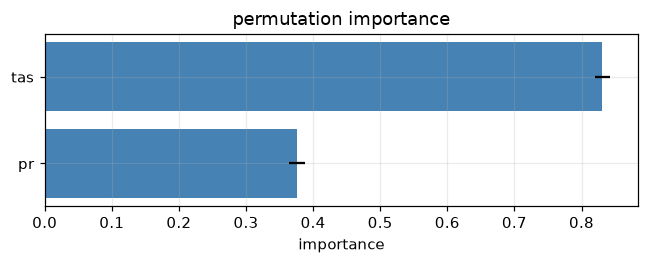

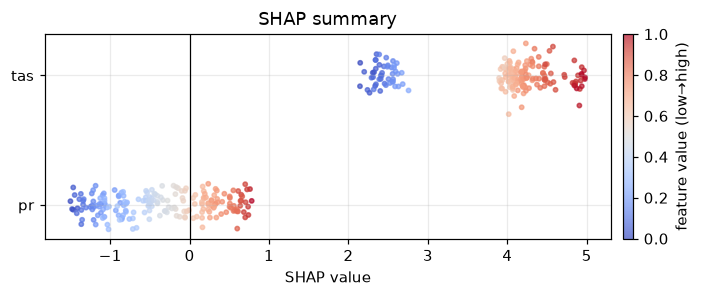

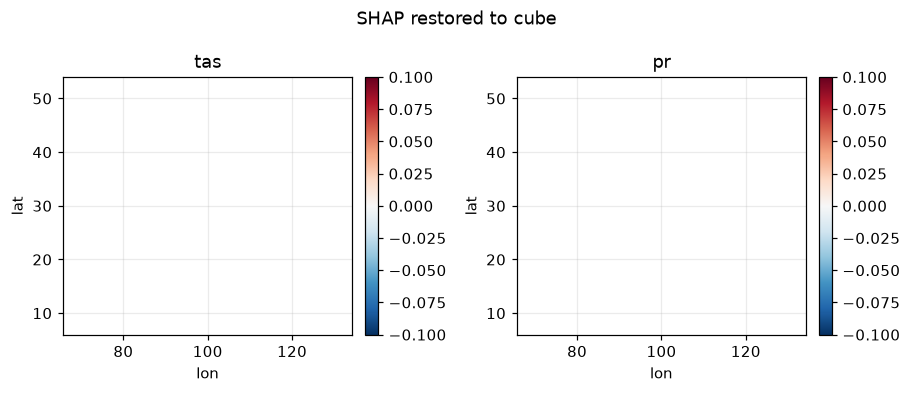

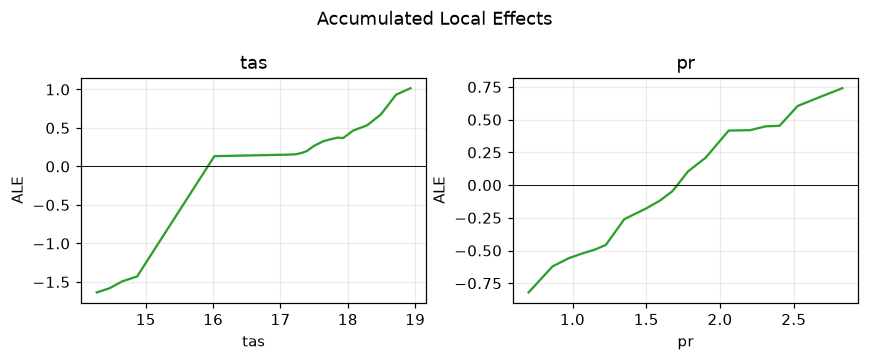

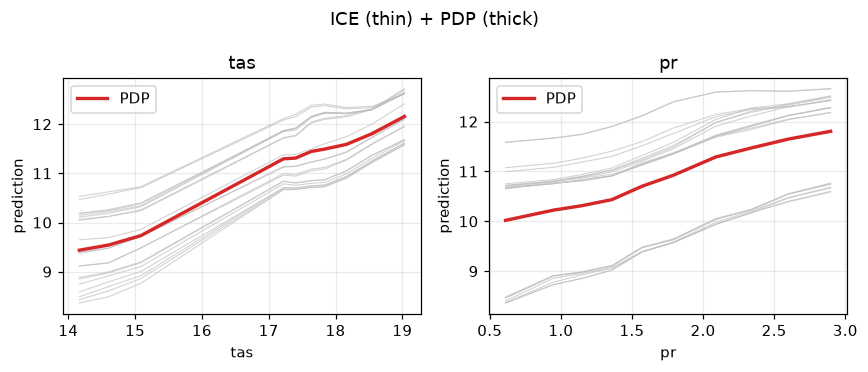

In [10]:
if "rf_importance" in result.artifacts:
    display(result.artifacts["rf_importance"])
    fig = plot_importance_bars(result.artifacts["rf_importance"], title="tree importance")
    plt.show()
if "permutation_importance" in result.artifacts:
    display(result.artifacts["permutation_importance"])
    fig = plot_importance_bars(result.artifacts["permutation_importance"], title="permutation importance")
    plt.show()

shap_res = result.artifacts.get("shap_result")
if shap_res is not None:
    xs = result.split.test.X[shap_res.sample_positions]
    fig = plot_shap_summary(shap_res.values, xs, shap_res.feature_names)
    plt.show()
if result.shap_cube is not None:
    fig = plot_shap_maps(result.shap_cube, time_index=0)
    plt.show()

if "ale" in result.artifacts:
    fig = plot_ale(result.artifacts["ale"])
    plt.show()
if "ice_pdp" in result.artifacts:
    fig = plot_ice_pdp(result.artifacts["ice_pdp"])
    plt.show()

## 6. Write the same artefacts the diagnostic would store

In [11]:
out = root / "outputs" / "esmvaltool_notebook"
save_result_files(result, out)
print("wrote", out)
print(sorted(p.name for p in out.iterdir()))
print(sorted(p.name for p in (out / "plots").iterdir()))

wrote /Users/huangfeini/Documents/rf_shap/outputs/esmvaltool_notebook
['metrics.csv', 'permutation_importance.csv', 'plots', 'prediction.nc', 'rf_importance.csv', 'shap.nc']
['ale.png', 'ice_pdp.png', 'permutation_importance.png', 'pred_vs_obs.png', 'prediction_maps.png', 'rf_importance.png', 'shap_maps.png', 'shap_summary.png']


## 7. Optional: local ACCESS-CM2 (skipped if files are missing)

Your CMIP6 copy is a **flat folder**, so `esmvaltool run` may not find it. This cell uses the same `x_files`/`y_file` path as `esmvaltool/run_local.py`.
Only a short time window and a coarse grid are used so the cell stays interactive.

ACCESS subset {'lat': 18, 'lon': 24, 'time': 24} ['huss', 'hurs', 'ps'] -> ['tas']


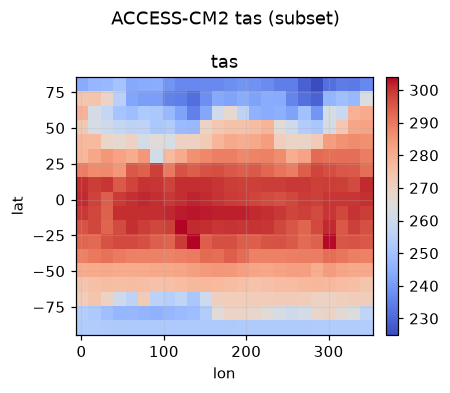

,ACCESS-CM2
n,2160.000000
r2,0.996836
rmse,1.291938
mae,0.750674
bias,-0.134817
ubrmse,1.284884
nse,0.996836
kge,0.984487
pearson_r,0.998532
mape,0.002782


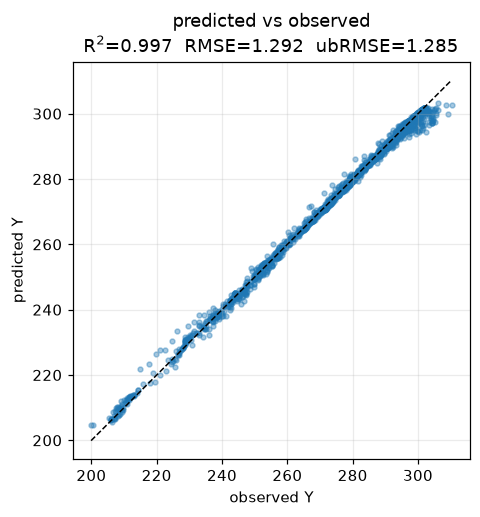

In [12]:
cmip = Path("/Users/huangfeini/Documents/esm_case_data/cmip6/ACCESS-CM2")
local = {
    "huss": cmip / "huss_Amon_ACCESS-CM2_historical_r1i1p1f1_198001-201412.nc",
    "hurs": cmip / "hurs_Amon_ACCESS-CM2_historical_r1i1p1f1_198001-201412.nc",
    "ps": cmip / "ps_Amon_ACCESS-CM2_historical_r1i1p1f1_198001-201412.nc",
}
y_local = cmip / "tas_Amon_ACCESS-CM2_historical_r1i1p1f1_198001-201412.nc"

if all(p.is_file() for p in [*local.values(), y_local]):
    Xl, Yl = load_xy_from_files({k: str(v) for k, v in local.items()}, str(y_local), y_name="tas")
    Xl = Xl.isel(time=slice(0, 24)).isel(lat=slice(None, None, 8), lon=slice(None, None, 8))
    Yl = Yl.isel(time=slice(0, 24)).isel(lat=slice(None, None, 8), lon=slice(None, None, 8))
    print("ACCESS subset", dict(Xl.sizes), list(Xl.data_vars), "->", list(Yl.data_vars))
    fig = plot_cube_maps(Yl, time_index=0, cmap="coolwarm", title="ACCESS-CM2 tas (subset)")
    plt.show()
    result_acc = run_pipeline_on_cubes(
        Xl,
        Yl,
        override={
            "sampling": {"n_samples": 800},
            "model": {"name": "extra_trees", "params": {"n_estimators": 60, "max_depth": 8, "n_jobs": -1}},
            "explain": {
                "shap": {"enabled": True, "max_samples": 200, "background_size": 40},
                "ale": False,
                "ice_pdp": False,
                "permutation_importance": False,
            },
        },
    )
    display(pd.Series(result_acc.metrics).to_frame("ACCESS-CM2"))
    fig = plot_pred_scatter(result_acc.split.test.y, result_acc.prediction, result_acc.metrics)
    plt.show()
else:
    print("ACCESS-CM2 files not found; skip local test.")